In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
data = load_breast_cancer(as_frame=True)

X = data.data

# Labels: 0-> Malignant , 1-> Benign
y = data.target

print("Dataset dimensions:", X.shape)
print("Top 5 instances:")
display(X.head())

print("\nDiagnosis distribution:")
print(y.value_counts().rename(index={
    0: "Malignant",
    1: "Benign"
}))

Dataset dimensions: (569, 30)
Top 5 instances:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Diagnosis distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [3]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape)
print("Dimensions after PCA:", X_pca.shape)

Original dimensions: (569, 30)
Dimensions after PCA: (569, 30)


In [4]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_table = pd.DataFrame({
    "Principal Component": np.arange(1, len(explained_variance) + 1),
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Explained Variance (%)": cumulative_variance * 100
})

display(variance_table.round(2))

print(
    "Number of components needed to explain at least 95% of the variance:",
    np.argmax(cumulative_variance >= 0.95) + 1
)

,Principal Component,Explained Variance (%),Cumulative Explained Variance (%)
0,1,44.27,44.27
1,2,18.97,63.24
2,3,9.39,72.64
3,4,6.60,79.24
4,5,5.50,84.73
5,6,4.02,88.76
6,7,2.25,91.01
7,8,1.59,92.60
8,9,1.39,93.99
9,10,1.17,95.16


Number of components needed to explain at least 95% of the variance: 10


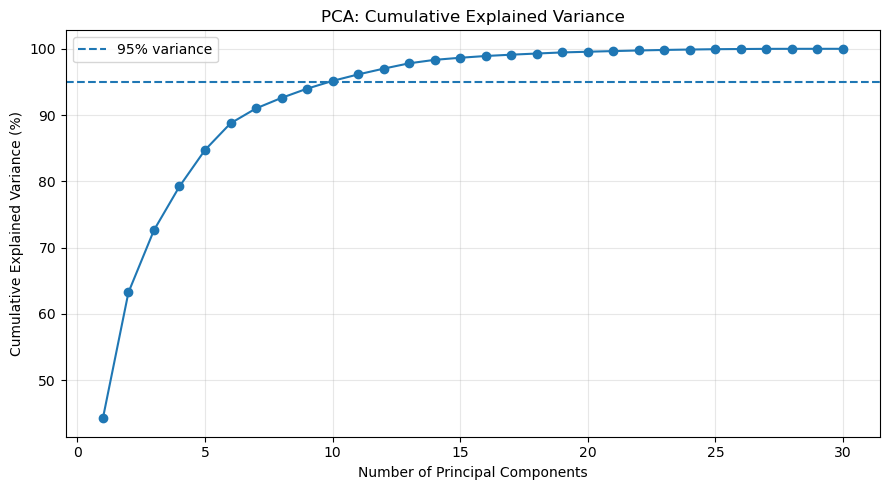

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.axhline(y=95, linestyle="--", label="95% variance")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA: Cumulative Explained Variance")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

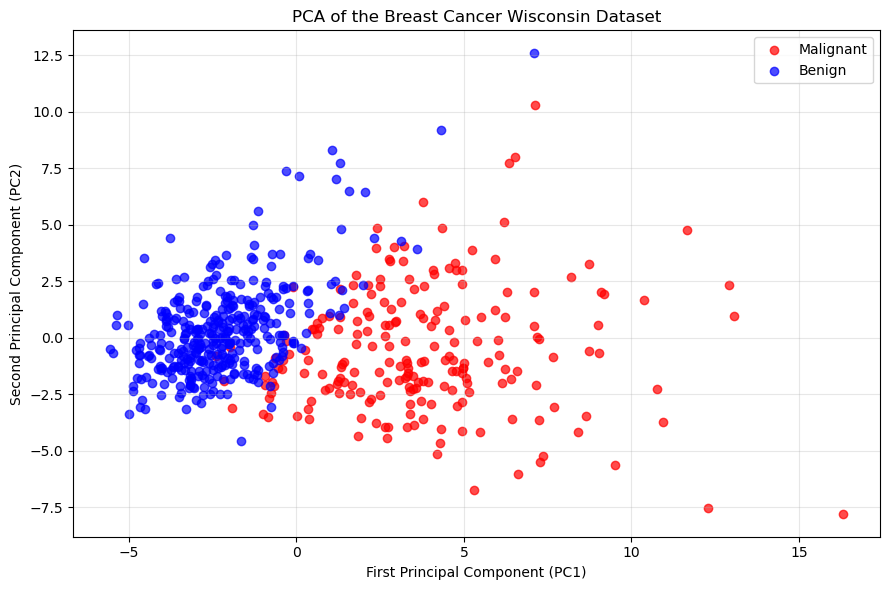

In [6]:
plt.figure(figsize=(9, 6))

colors = {0: "red", 1: "blue"}
labels = {0: "Malignant", 1: "Benign"}

for diagnosis in [0, 1]:
    mask = (y == diagnosis)

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        c=colors[diagnosis],
        label=labels[diagnosis],
        alpha=0.7
    )

plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("PCA of the Breast Cancer Wisconsin Dataset")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()